# 02 — Satellite data inventory and SMAP quality pilot

**CHT Forest Ecohydrology and Machine Learning** — Rangamati, Bandarban and Khagrachhari.

This notebook checks yearly Earth Engine image counts and tests SMAP quality/availability during January and July 2020. It reads but never modifies your district shapefile. It does **not** download imagery, train a model, export Earth Engine assets, or update GitHub.

**Scientific caution:** image counts are not valid-data counts. SMAP's 9 km grid posting is not independent 9 km measurement resolution. This pilot is not ground validation.

## 1. Initialize Earth Engine with your project configuration

Run with the same Python kernel as Notebooks 00 and 01. This inventory uses a simplified *in-memory* union of the three polygons; no source file is changed.

In [3]:
from pathlib import Path
import json
import ee
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from shapely.geometry import mapping
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), Path.cwd().parent) if (p / 'configs' / 'study_config.json').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Launch Jupyter from the project root or notebooks directory.')
CONFIG = json.loads((ROOT / 'configs' / 'study_config.json').read_text(encoding='utf-8'))
districts = gpd.read_file(ROOT / CONFIG['boundary_relative_path'])
assert districts.crs is not None and districts.geometry.is_valid.all()
assert set(districts[CONFIG['district_name_field']]) == set(CONFIG['expected_districts'])
# Simplify ONLY the temporary inventory geometry (~0.001 degrees); original boundaries are untouched.
geometry = districts.to_crs('EPSG:4326').geometry.union_all().simplify(0.001, preserve_topology=True)
ee.Initialize(project=CONFIG['gee_project_id'])
AOI = ee.Geometry(mapping(geometry))
START, END = CONFIG['study_start'], CONFIG['study_end_exclusive']
assert START.endswith('-01-01') and END.endswith('-01-01'), 'Full calendar years required for the inventory table.'
YEARS = range(int(START[:4]), int(END[:4]))
SAVE_RESULTS = True  # Saves only small tables under local outputs/tables/
print('Earth Engine project:', CONFIG['gee_project_id'])
print('Study window:', START, 'to', END, '(exclusive)')
print('Districts:', districts[CONFIG['district_name_field']].tolist())

Earth Engine project: axial-paratext-491911-b6
Study window: 2017-01-01 to 2023-01-01 (exclusive)
Districts: ['Bandarban', 'Khagrachhari', 'Rangamati']


## 2. Study-period data availability

SMAP v005 covers the proposed 2017–2022 historical experiment. The public GEE catalog states that new SMAP data starting **2023-12-04** are in v006; we will not silently combine product versions. For a subsequent contemporary experiment, we can explicitly assess v006.

| Role | Catalog ID | Key methodological caveat |
|---|---|---|
| Target soil moisture | `NASA/SMAP/SPL3SMP_E/005` | 9 km grid, masked/QA-flagged retrievals |
| Rainfall | `UCSB-CHG/CHIRPS/DAILY` | Station-informed gridded rainfall, not independent field validation |
| Weather | `ECMWF/ERA5_LAND/DAILY_AGGR` | Reanalysis data, not measured ground truth |
| Vegetation | `MODIS/061/MOD13Q1` | NDVI/EVI at 16-day intervals with QA |
| Radar | `COPERNICUS/S1_GRD` | Ascending/descending orbit, radar geometry and terrain effects matter |

Official documentation: [SMAP v005](https://developers.google.com/earth-engine/datasets/catalog/NASA_SMAP_SPL3SMP_E_005), [SMAP v006](https://developers.google.com/earth-engine/datasets/catalog/NASA_SMAP_SPL3SMP_E_006), [CHIRPS daily](https://developers.google.com/earth-engine/datasets/catalog/UCSB-CHG_CHIRPS_DAILY), [ERA5-Land](https://developers.google.com/earth-engine/datasets/catalog/ECMWF_ERA5_LAND_DAILY_AGGR), [MODIS vegetation](https://developers.google.com/earth-engine/datasets/catalog/MODIS_061_MOD13Q1), [Sentinel-1](https://developers.google.com/earth-engine/datasets/catalog/COPERNICUS_S1_GRD).

**Output meaning:** Sentinel-1 counts are scenes; MODIS counts are composites/tiles; CHIRPS and ERA5 counts are daily images; none is a guarantee of spatial coverage or QA validity.

In [4]:
S1 = (ee.ImageCollection('COPERNICUS/S1_GRD')
      .filter(ee.Filter.eq('instrumentMode', 'IW'))
      .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
      .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VH')))
COLLECTIONS = {
    'SMAP v005': ee.ImageCollection(CONFIG['smap_collection_for_period']),
    'CHIRPS daily v2': ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY'),
    'ERA5-Land daily': ee.ImageCollection('ECMWF/ERA5_LAND/DAILY_AGGR'),
    'MODIS NDVI 16-day': ee.ImageCollection('MODIS/061/MOD13Q1'),
    'Sentinel-1 IW VV+VH': S1,
}
# Evaluate all annual counts in one server-side dictionary request.
query = ee.Dictionary({name: ee.Dictionary({
    str(y): collection.filterBounds(AOI).filterDate(f'{y}-01-01', f'{y+1}-01-01').size()
    for y in YEARS
}) for name, collection in COLLECTIONS.items()})
annual_counts = pd.DataFrame({k: pd.Series(v, dtype='int64') for k, v in query.getInfo().items()})
annual_counts.index = annual_counts.index.astype(int)
annual_counts.index.name = 'year'
annual_counts = annual_counts.sort_index()
display(annual_counts)
print('Counts show collection availability only, NOT valid coverage.')

,CHIRPS daily v2,ERA5-Land daily,MODIS NDVI 16-day,SMAP v005,Sentinel-1 IW VV+VH
year,,,,,
2017,365,365,23,365,182
2018,365,365,23,365,209
2019,365,365,23,332,183
2020,366,366,23,366,231
2021,365,365,23,365,236
2022,365,365,23,317,232


Counts show collection availability only, NOT valid coverage.


## 3. Compare Sentinel-1 orbit directions

We must avoid mixing different look directions without considering geometric differences. This cell counts VV+VH IW scenes for each orbit direction.

In [5]:
orbit_query = ee.Dictionary({direction: ee.Dictionary({
    str(y): S1.filterBounds(AOI).filterDate(f'{y}-01-01', f'{y+1}-01-01')
             .filter(ee.Filter.eq('orbitProperties_pass', direction)).size()
    for y in YEARS
}) for direction in ('ASCENDING', 'DESCENDING')})
orbit_counts = pd.DataFrame({k: pd.Series(v, dtype='int64')
                             for k, v in orbit_query.getInfo().items()})
orbit_counts.index = orbit_counts.index.astype(int)
orbit_counts.index.name = 'year'
orbit_counts = orbit_counts.sort_index()
display(orbit_counts)

,ASCENDING,DESCENDING
year,,
2017,105,77
2018,112,97
2019,122,61
2020,127,104
2021,122,114
2022,118,114


## 4. Small SMAP AM quality pilot: January versus July 2020

For each available image, estimate the fraction of sampled 9 km grid cells in the study area with non-missing `soil_moisture_am`, QA flag `retrieval_qual_flag_am == 0`, and a value in [0, 1]. This is a **conservative first-pass** QA test; check exact flag interpretation against the NSIDC product user guide before full analysis.

Calendar days with no image are `NaN` (not zero), to distinguish absent imagery from bad retrievals. January/July are provisional contrasting months, not a complete seasonality assessment.

In [6]:
PILOT_MONTHS = [('2020-01-01', '2020-02-01'), ('2020-07-01', '2020-08-01')]
assert all(START <= a < b <= END for a, b in PILOT_MONTHS), 'Choose pilot months inside study dates.'
SMAP = COLLECTIONS['SMAP v005']

def to_qa_feature(item):
    image = ee.Image(item)
    soil = image.select('soil_moisture_am')
    qa = image.select('retrieval_qual_flag_am')
    valid_mask = (soil.mask().And(qa.mask()).And(qa.eq(0))
                  .And(soil.gte(0)).And(soil.lte(1)))
    # Retain SMAP projection; treat masked/non-QA-passing cells as 0 for the area proportion.
    indicator = soil.multiply(0).add(1).updateMask(valid_mask).unmask(0).rename('valid')
    proportion = indicator.reduceRegion(
        reducer=ee.Reducer.mean(), geometry=AOI, scale=9000,
        maxPixels=1000000, tileScale=2).get('valid')
    return ee.Feature(None, {'date': image.date().format('YYYY-MM-dd'),
                             'valid_fraction': proportion})

frames = []
for a, b in PILOT_MONTHS:
    collection = SMAP.filterBounds(AOI).filterDate(a, b).sort('system:time_start')
    n = collection.size().getInfo()
    print(a[:7], 'available SMAP images:', n)
    if n:
        features = ee.FeatureCollection(collection.toList(n).map(to_qa_feature)).getInfo()['features']
        observations = pd.DataFrame([f['properties'] for f in features])
        observations['date'] = pd.to_datetime(observations['date'])
        # If there are two scenes on a calendar day, average their scene-based fractions.
        observations = observations.groupby('date', as_index=False)['valid_fraction'].mean()
    else:
        observations = pd.DataFrame({'date': pd.Series(dtype='datetime64[ns]'),
                                     'valid_fraction': pd.Series(dtype='float64')})
    calendar = pd.DataFrame({'date': pd.date_range(a, pd.Timestamp(b) - pd.Timedelta(days=1))})
    frame = calendar.merge(observations, on='date', how='left')
    frame['month'] = a[:7]
    frame['has_scene'] = frame['date'].isin(observations['date'])
    frames.append(frame)
pilot = pd.concat(frames, ignore_index=True)
pilot['valid_area_pct'] = pilot['valid_fraction'] * 100
display(pilot.head())

2020-01 available SMAP images: 31
2020-07 available SMAP images: 31


,date,valid_fraction,month,has_scene,valid_area_pct
0,2020-01-01,0.153935,2020-01,True,15.393460
1,2020-01-02,0.153183,2020-01,True,15.318283
2,2020-01-03,0.000000,2020-01,True,0.000000
3,2020-01-04,0.124638,2020-01,True,12.463794
4,2020-01-05,0.160922,2020-01,True,16.092157


,days,days_with_scene,days_with_fraction,mean_valid_area_pct,median_valid_area_pct
month,,,,,
2020-01,31,31,31,8.45,12.46
2020-07,31,31,31,3.63,0.00


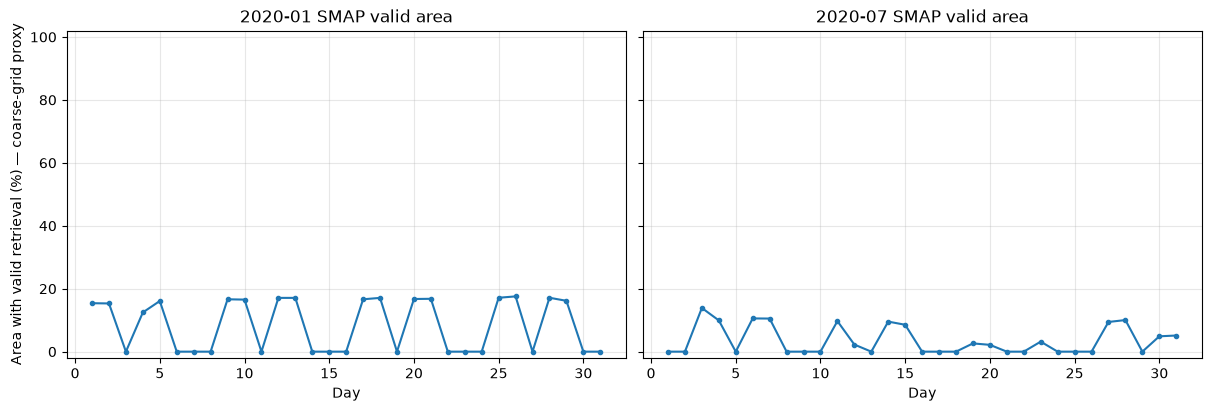

In [7]:
pilot_summary = pilot.groupby('month').agg(
    days=('date', 'size'), days_with_scene=('has_scene', 'sum'),
    days_with_fraction=('valid_area_pct', 'count'),
    mean_valid_area_pct=('valid_area_pct', 'mean'),
    median_valid_area_pct=('valid_area_pct', 'median')
).round(2)
display(pilot_summary)
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True, constrained_layout=True)
for ax, (month, frame) in zip(axs, pilot.groupby('month')):
    ax.plot(frame['date'].dt.day, frame['valid_area_pct'], 'o-', markersize=3)
    ax.set(title=month + ' SMAP valid area', xlabel='Day', ylim=(-2, 102))
    ax.grid(alpha=0.3)
axs[0].set_ylabel('Area with valid retrieval (%) — coarse-grid proxy')
plt.show()

## 5. Save four small local CSV tables

This writes to `outputs/tables/` on your PC only if `SAVE_RESULTS=True`. It does not export any satellite images or change the GitHub repository.

In [8]:
if SAVE_RESULTS:
    destination = ROOT / 'outputs' / 'tables'
    destination.mkdir(parents=True, exist_ok=True)
    annual_counts.to_csv(destination / '02_annual_collection_counts.csv')
    orbit_counts.to_csv(destination / '02_sentinel1_orbit_counts.csv')
    pilot.to_csv(destination / '02_smap_pilot_daily_coverage.csv', index=False)
    pilot_summary.to_csv(destination / '02_smap_pilot_month_summary.csv')
    print('Saved four CSV tables to:', destination.resolve())
else:
    print('SAVE_RESULTS=False: no files written.')

Saved four CSV tables to: D:\Gihub_Projects\cht-forest-ecohydrology-ml-starter\cht-forest-ecohydrology-ml\outputs\tables
